# How well do Tg models generalize to chemically dissimilar polymers?

**Research question.** Machine-learning models for the glass transition temperature (Tg)
are usually scored on a *random* train/test split. But when a model is used to screen new
polymers, those polymers are often chemically different from anything in the training set.
This notebook asks two things:

1. How much worse do Tg models get on **chemically dissimilar** polymers?
2. Do their **uncertainty estimates stay calibrated** when that happens - and is the
   predicted uncertainty larger for out-of-distribution polymers?

**Data.** 511 polymers with Tg from the Kaggle *NeurIPS - Open Polymer Prediction 2025*
training set, plus 46 polymers from `dataset3.csv`, kept aside as an external test set.
With so few data points, every method here is chosen to be simple, cheap to
cross-validate and hard to overfit.

**Outline**
1. Set up  ·  2. Load data  ·  3. Look at the data  ·  4. Duplicates  ·  5. Features
6. First look: one random split  ·  7. A chemically dissimilar split  ·  8. Comparing models on three test settings
9. Uncertainty and calibration  ·  10. Interpretability  ·  11. Conclusions

Reusable code lives in `src/polymer_tg/`; this notebook tells the story.
Run it top to bottom from the `notebooks/` folder (≈ 7 minutes on a laptop).
Figures are written to `figures/`.

## 1. Set up

The original notebook ran `!pip install rdkit` (needed on Kaggle). Dependencies are now
listed in `requirements.txt` instead, so the notebook runs the same way everywhere:
`pip install -r requirements.txt`.

In [1]:
## 1. set up

import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors

# Make the project's own code in ../src importable.
sys.path.insert(0, "../src")
from polymer_tg import SEED
from polymer_tg.data import canonicalize, load_tg_data, deduplicate, remove_overlap
from polymer_tg.features import (DESCRIPTORS, ALL_DESCRIPTORS, featurize,
                                 clean_descriptors, morgan_features,
                                 morgan_fingerprint_objects)
from polymer_tg.splits import (BUTINA_CUTOFF, butina_clusters, random_cv_splits,
                               cluster_cv_splits, max_similarity_to_reference,
                               test_fold_similarities)
from polymer_tg.evaluation import (make_models, regression_metrics, evaluate_all,
                                   format_summary)
from polymer_tg.uncertainty import (run_uncertainty_experiment, coverage_table,
                                    coverage_curve, no_skill_interval)
from polymer_tg.plotting import SETTING_COLORS, NEUTRAL, apply_style, save_figure

# Reproducibility: one seed for numpy and every scikit-learn model / split.
np.random.seed(SEED)

# RDKit prints a warning for every '*' atom in some descriptors; they are
# expected for polymer SMILES and would flood the output.
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
apply_style()
FIG_DIR = "../figures"

## 2. Load data

Only rows of `train.csv` with a measured Tg are kept. `load_tg_data` also adds a
`canonical_smiles` column (RDKit's standard way of writing each SMILES), which is needed
to find duplicates in section 4.

In [2]:
## 2. Load data

DATA_DIR = "../data"

train_tg, ext = load_tg_data(DATA_DIR)

print("Tg training samples", len(train_tg))
print("External samples", len(ext))
train_tg.head()

Tg training samples 511
External samples 46


,id,SMILES,Tg,canonical_smiles
0,10142210,*NC(C)C(=O)NCC(=O)NCC(*)=O,208.639749,*NC(C)C(=O)NCC(=O)NCC(*)=O
1,13838538,*CCCCCCSSCCCCSS*,-41.266724,*CCCCCCSSCCCCSS*
2,16498242,*C=CCCCCCCCC*,-17.282022,*C=CCCCCCCCC*
3,30582999,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCNC(=O)c2ccc(C(=...,4.250403,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCNC(=O)c2ccc(C(=...
4,36217683,*c1nc2cc3sc(-c4cc(OCCCCCC)c(*)cc4OCCCCCC)nc3cc2s1,168.526313,*c1nc2cc3sc(-c4cc(OCCCCCC)c(*)cc4OCCCCCC)nc3cc2s1


## 3. Look at the data

The external set has a higher mean Tg than the training set. That is already a form of
distribution shift: even before looking at chemistry, the model will be asked to predict
more high-Tg polymers than it was trained on.

In [3]:
## 3. Look at the data

pd.DataFrame({
    "Training":train_tg["Tg"].describe(),
    "External":ext["Tg"].describe(),
}).round(1)

,Training,External
count,511.0,46.0
mean,96.5,135.7
std,111.2,103.8
min,-148.0,-7.2
25%,13.7,57.1
50%,74.0,109.4
75%,161.1,197.7
max,472.2,422.0


Saved ../figures/01_tg_distribution.png


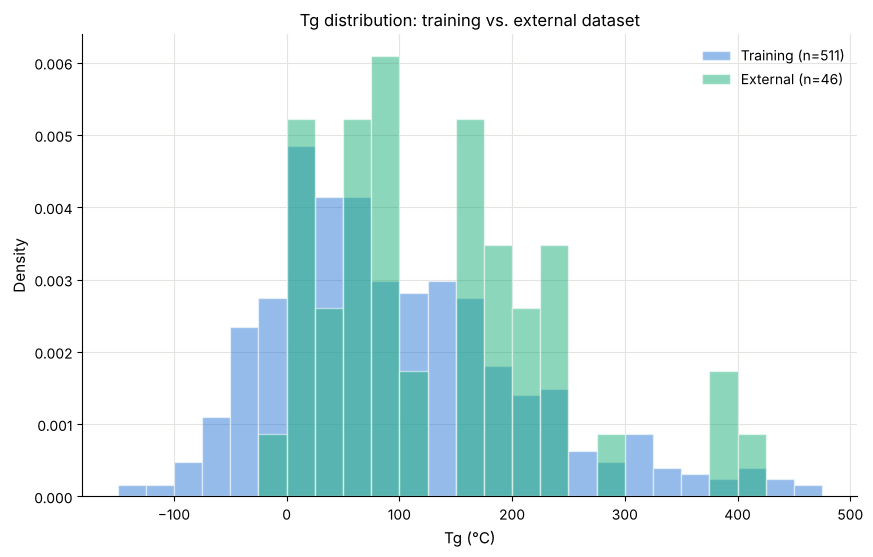

In [4]:
bins = np.arange(-150, 500, 25)
fig, ax = plt.subplots(figsize=(10,6))
for name, df in [("Training", train_tg), ("External", ext)]:
    color = SETTING_COLORS["Random CV"] if name == "Training" else SETTING_COLORS["External"]
    ax.hist(df["Tg"], bins=bins, density=True, alpha=0.5, color=color,
            edgecolor="white", label=f'{name} (n={len(df)})')
ax.set(xlabel="Tg (°C)", ylabel="Density", title="Tg distribution: training vs. external dataset")
ax.legend()
save_figure(fig, "01_tg_distribution", FIG_DIR);

## 4. Check for duplicates

A polymer that appears twice could end up in both the training and the test part of a
split, which would make the model look better than it is. The original check is kept;
`deduplicate` and `remove_overlap` then actually *act* on the result (merge duplicates by
averaging Tg; drop external polymers that are also in training). In this data no
duplicates are found, so nothing changes - but the pipeline stays safe if the data is
updated.

In [5]:
## 4. Check for duplicates
# (canonical_smiles was already computed by load_tg_data using canonicalize())

n_dup = train_tg["canonical_smiles"].duplicated().sum()
n_overlap = ext["canonical_smiles"].isin(train_tg["canonical_smiles"]).sum()
print(f"Duplicates within training set: {n_dup}")
print(f"External polymers also in training set: {n_overlap}")
print(f"Duplicates within external set: {ext['canonical_smiles'].duplicated().sum()}")

train_tg = deduplicate(train_tg, "Training")
ext = deduplicate(ext, "External")
ext = remove_overlap(train_tg, ext)

Duplicates within training set: 0
External polymers also in training set: 0
Duplicates within external set: 0
Training: 511 rows -> 511 rows (0 invalid SMILES, 0 duplicates merged)
External: 46 rows -> 46 rows (0 invalid SMILES, 0 duplicates merged)
External polymers also in training (removed from external): 0


## 5. Featurize

Three feature sets are compared:

| Feature set | Size | What it describes |
|---|---|---|
| 5 descriptors (original) | 5 | Physically motivated: flexibility, rings, sp3 fraction, mass, polarity |
| All RDKit descriptors | ~180 after cleaning | Many more physico-chemical properties (redundant, correlated) |
| Morgan fingerprint | 2048 bits | Which small substructures (radius 2) are present |

### 5a. Five hand-picked descriptors (original)

In [6]:
## 5. Featurize
# DESCRIPTORS and featurize() now live in src/polymer_tg/features.py (unchanged).

X_train = featurize(train_tg["canonical_smiles"])
X_ext = featurize(ext["canonical_smiles"])
y_train = train_tg["Tg"]
y_ext = ext["Tg"]

print("X_train:", X_train.shape, " X_ext:", X_ext.shape)
X_train.head()

X_train: (511, 5)  X_ext: (46, 5)


,rotatable_bonds,aromatic_rings,fraction_csp3,repeat_unit_MW,TPSA
0,6,0,0.571429,185.183,87.30
1,13,0,1.000000,268.538,0.00
2,8,0,0.800000,138.254,0.00
3,17,2,0.428571,494.588,110.80
4,13,4,0.461538,466.672,44.24


Correlation of each descriptor with Tg. `fraction_csp3` is strongly negative (more
saturated, flexible carbon → lower Tg) and `aromatic_rings` positive (stiff rings → higher
Tg), as polymer physics would predict.

In [7]:
X_train.corrwith(y_train).sort_values().round(2)

fraction_csp3     -0.61
rotatable_bonds   -0.32
TPSA               0.21
repeat_unit_MW     0.25
aromatic_rings     0.61
dtype: float64

In [8]:
pd.concat([X_train, y_train], axis=1).corr().round(2)

,rotatable_bonds,aromatic_rings,fraction_csp3,repeat_unit_MW,TPSA,Tg
rotatable_bonds,1.00,0.09,0.30,0.63,0.36,-0.32
aromatic_rings,0.09,1.00,-0.68,0.72,0.43,0.61
fraction_csp3,0.30,-0.68,1.00,-0.29,-0.30,-0.61
repeat_unit_MW,0.63,0.72,-0.29,1.00,0.67,0.25
TPSA,0.36,0.43,-0.30,0.67,1.00,0.21
Tg,-0.32,0.61,-0.61,0.25,0.21,1.00


### 5b. All RDKit descriptors

`clean_descriptors` drops descriptors that fail on the `*` atoms or are constant, using the
training set only, and log-compresses a few descriptors with astronomically large values
(e.g. `Ipc`) that would otherwise break the linear model.

In [9]:
X_full_raw = featurize(train_tg["canonical_smiles"], ALL_DESCRIPTORS)
X_ext_full_raw = featurize(ext["canonical_smiles"], ALL_DESCRIPTORS)
X_full, X_ext_full = clean_descriptors(X_full_raw, X_ext_full_raw)
print("RDKit descriptors:", X_full_raw.shape[1], "-> usable:", X_full.shape[1])

RDKit descriptors: 217 -> usable: 181


### 5c. Morgan fingerprints

A Morgan fingerprint looks at every atom and its neighbourhood up to 2 bonds away, hashes
each of these small fragments to one of 2048 positions, and sets that bit to 1. Two polymers
with many shared fragments have many shared bits. The same fingerprints are used later to
measure **chemical similarity** (Tanimoto similarity = shared bits / bits present in either).

In [10]:
X_morgan = morgan_features(train_tg["canonical_smiles"])
X_ext_morgan = morgan_features(ext["canonical_smiles"])

# Fingerprint objects (same bits) for fast similarity calculations.
fps_train = morgan_fingerprint_objects(train_tg["canonical_smiles"])
fps_ext = morgan_fingerprint_objects(ext["canonical_smiles"])

bits_used = (X_morgan.sum() > 0).sum()
print("Morgan matrix:", X_morgan.shape, f"- {bits_used} bits are set in at least one polymer")
print(f"Average bits set per polymer: {X_morgan.sum(axis=1).mean():.0f}")

Morgan matrix: (511, 2048) - 1603 bits are set in at least one polymer
Average bits set per polymer: 34


## 6. First look: one random 80/20 split

This is the original comparison (one random split + external set), now with RMSE as well
and with **Ridge regression** instead of plain linear regression: plain least squares has no
unique solution when there are more features (2048 fingerprint bits) than training polymers,
while Ridge does. On the 5 descriptors the two give almost identical
results.

A single split of ~100 test polymers is noisy, so from section 8 on we use 5-fold
cross-validation instead.

In [11]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X_train, y_train, test_size=0.2, random_state=SEED)
print("Train:", len(X_tr), " Test:", len(X_te))

Train: 408  Test: 103


In [12]:
models = make_models()

results = []
for name, model in models.items():
    model.fit(X_tr, y_tr)
    for eval_set, X, y in [("Random test", X_te, y_te), ("External", X_ext, y_ext)]:
        pred = model.predict(X)
        results.append({"model": name, "eval_set": eval_set, **regression_metrics(y, pred)})

pd.DataFrame(results).round(2)

,model,eval_set,MAE,RMSE,R2
0,Ridge regression,Random test,60.51,74.93,0.41
1,Ridge regression,External,58.96,76.12,0.45
2,Random forest,Random test,63.82,79.76,0.33
3,Random forest,External,55.12,74.13,0.48


Note that on this particular split Ridge looks *better* than the random forest, while the
5-fold results in section 8 show the opposite in every cross-validated comparison. That is
exactly why a single ~100-polymer test set is not enough to choose between models.

## 7. A chemically dissimilar split

**Idea.** Group chemically similar polymers into clusters, then make sure each cluster is
entirely in the training part *or* entirely in the test part. The model is then always
tested on chemistry it has not seen.

**Why fingerprint clustering and not Murcko scaffolds?** A Murcko scaffold is the ring
system of a molecule. Below, 22% of the polymers have *no rings at all* and would all share
the same empty scaffold, forming one giant group; another 15% share a single benzene ring.
Scaffolds are too coarse for polymer repeat units. Butina clustering on Morgan
fingerprints (distance cutoff 0.7, i.e. a polymer joins a cluster if its Tanimoto similarity
to the cluster centre is ≥ 0.3) gives many small, chemically coherent clusters instead.

In [13]:
from rdkit.Chem.Scaffolds import MurckoScaffold

scaffolds = train_tg["canonical_smiles"].apply(
    lambda s: MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(s)))
print(f"Murcko scaffolds: {scaffolds.nunique()} unique; "
      f"{(scaffolds == '').mean():.0%} of polymers have no ring (empty scaffold); "
      f"{(scaffolds == 'c1ccccc1').mean():.0%} have only a benzene ring")

clusters = butina_clusters(fps_train, cutoff=BUTINA_CUTOFF)
cluster_sizes = pd.Series(clusters).value_counts()
print(f"\nButina clusters (cutoff {BUTINA_CUTOFF}): {len(cluster_sizes)} clusters")
print(f"Largest clusters: {cluster_sizes.head(5).tolist()}  "
      f"(largest = {cluster_sizes.iloc[0] / len(clusters):.0%} of polymers)")
print(f"Singletons (cluster of one polymer): {(cluster_sizes == 1).sum()}")

Murcko scaffolds: 248 unique; 22% of polymers have no ring (empty scaffold); 15% have only a benzene ring

Butina clusters (cutoff 0.7): 139 clusters
Largest clusters: [76, 28, 24, 24, 19]  (largest = 15% of polymers)
Singletons (cluster of one polymer): 73


The three test settings used for the rest of the notebook:

- **Random CV** - 5 random folds (the usual, optimistic evaluation).
- **Cluster CV** - 5 folds made of whole Butina clusters (chemically dissimilar test polymers).
- **External** - train on all 511 polymers, test on the 46 in `dataset3.csv`.

To check that the cluster split really is harder, we compute for every test polymer the
Tanimoto similarity to its **nearest neighbour in the training data** of that fold.

In [14]:
cv_settings = {
    "Random CV": random_cv_splits(len(train_tg)),
    "Cluster CV": cluster_cv_splits(clusters),
}
for setting, splits in cv_settings.items():
    print(f"{setting}: test fold sizes {[len(test) for _, test in splits]}")

similarity = {
    "Random CV": test_fold_similarities(fps_train, cv_settings["Random CV"]),
    "Cluster CV": test_fold_similarities(fps_train, cv_settings["Cluster CV"]),
    "External": max_similarity_to_reference(fps_ext, fps_train),
}
pd.DataFrame({k: pd.Series(v).describe(percentiles=[0.1, 0.5, 0.9])
              for k, v in similarity.items()}).round(2)

Random CV: test fold sizes [103, 102, 102, 102, 102]
Cluster CV: test fold sizes [87, 135, 114, 80, 95]


,Random CV,Cluster CV,External
count,511.00,511.00,46.00
mean,0.52,0.41,0.49
std,0.18,0.14,0.18
min,0.17,0.16,0.18
10%,0.31,0.26,0.28
50%,0.50,0.39,0.46
90%,0.79,0.60,0.74
max,1.00,0.96,0.89


Saved ../figures/02_similarity_to_training.png


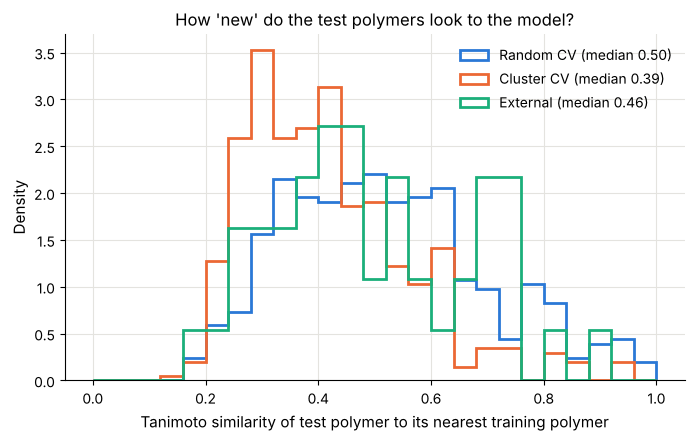

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, 1, 26)
for setting, sims in similarity.items():
    ax.hist(sims, bins=bins, density=True, histtype="step", linewidth=2,
            color=SETTING_COLORS[setting],
            label=f"{setting} (median {np.median(sims):.2f})")
ax.set(xlabel="Tanimoto similarity of test polymer to its nearest training polymer",
       ylabel="Density",
       title="How 'new' do the test polymers look to the model?")
ax.legend(loc="upper right")
save_figure(fig, "02_similarity_to_training", FIG_DIR);

The cluster split clearly shifts test polymers towards lower similarity (median ≈ 0.39 vs
0.50 for random folds). The external set sits **in between** (median ≈ 0.46): it is only
mildly dissimilar in chemistry, but - as section 3 showed - it is shifted towards higher Tg.
So the three settings probe different kinds of shift: none (random), chemical (cluster),
and mostly target-range (external).

## 8. Comparing feature sets and models on all three test settings

`evaluate_all` (a generalised version of the original `evaluate()` function) runs every
combination of feature set × model × test setting. For the CV settings the table shows
**mean ± standard deviation over the 5 folds**; for the external set it shows the value on
the 46 polymers ± a **bootstrap** standard deviation (resampling the 46 polymers 1000 times),
so all error bars mean roughly "how much would this number move with a different test set".

In [16]:
feature_sets = {
    "5 descriptors": (X_train, X_ext),
    "All RDKit descriptors": (X_full, X_ext_full),
    "Morgan fingerprint": (X_morgan, X_ext_morgan),
}

summary, predictions = evaluate_all(feature_sets, y_train, y_ext, cv_settings)
format_summary(summary)

setting                                  Random CV                             Cluster CV                               External                            
                                               MAE         RMSE           R2          MAE         RMSE           R2          MAE          RMSE            R2
features              model                                                                                                                                 
5 descriptors         Random forest     56.5 ± 7.2   72.3 ± 8.0  0.56 ± 0.13   59.5 ± 8.4   75.6 ± 9.8  0.48 ± 0.16   51.9 ± 7.0    69.9 ± 8.4   0.54 ± 0.14
                      Ridge regression  61.6 ± 7.3   77.2 ± 8.9  0.51 ± 0.07   63.9 ± 6.3   80.2 ± 6.8  0.42 ± 0.15   58.9 ± 7.4   76.5 ± 10.6   0.44 ± 0.09
All RDKit descriptors Random forest     51.7 ± 6.3   67.5 ± 8.2  0.62 ± 0.08   53.7 ± 7.4   69.2 ± 9.2  0.56 ± 0.13   51.9 ± 6.4    67.1 ± 8.0   0.57 ± 0.13
                      Ridge regression  56.7 ± 6.7  75.1 ± 10.9  0.53 ± 0.12  58.9 ± 10.0  77.4 ± 14.0  0.45 ± 0.19  73.1 ± 12.2  108.8 ± 23.1  -0.12 ± 0.66
Morgan fingerprint    Random forest     54.4 ± 5.7   71.2 ± 6.4  0.57 ± 0.11   58.3 ± 6.8   74.9 ± 9.4  0.48 ± 0.19   61.9 ± 7.4    79.7 ± 8.4   0.40 ± 0.15
                      Ridge regression  58.8 ± 6.3   75.9 ± 7.7  0.52 ± 0.07   60.7 ± 7.6   79.9 ± 8.9  0.42 ± 0.15   59.0 ± 8.0    78.7 ± 9.7   0.41 ± 0.12

In [17]:
# A "no-skill" reference: always predict the training-set mean Tg.
# Any useful model must beat this MAE.
no_skill = {}
for setting, splits in cv_settings.items():
    no_skill[setting] = np.mean([np.mean(np.abs(y_train.values[te] - y_train.values[tr].mean()))
                                 for tr, te in splits])
no_skill["External"] = np.mean(np.abs(y_ext - y_train.mean()))
pd.Series(no_skill, name="MAE of predicting the mean (°C)").round(1)

Random CV     88.2
Cluster CV    89.9
External      83.4
Name: MAE of predicting the mean (°C), dtype: float64

Saved ../figures/03_model_comparison_mae.png


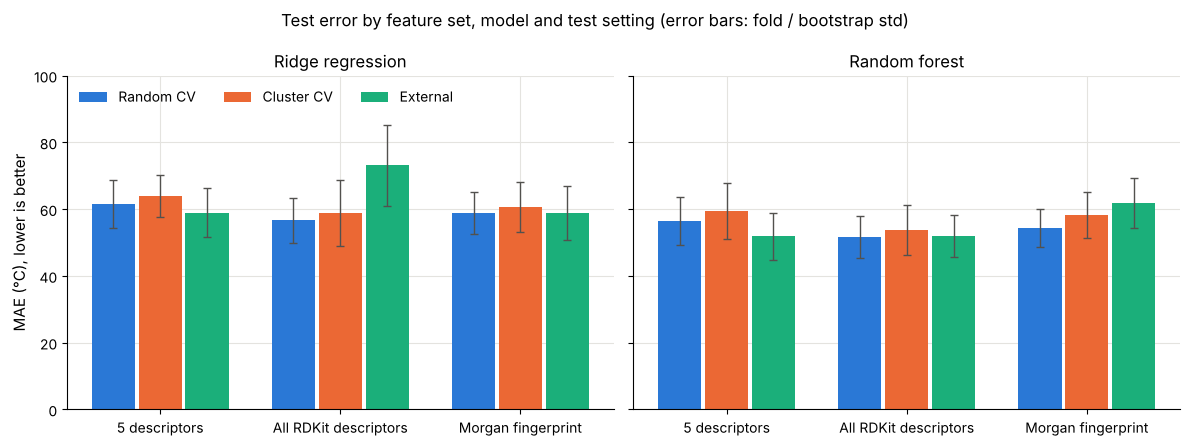

In [18]:
order = ["Random CV", "Cluster CV", "External"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
width = 0.26
for ax, model_name in zip(axes, ["Ridge regression", "Random forest"]):
    sub = summary[summary["model"] == model_name]
    x = np.arange(len(feature_sets))
    for i, setting in enumerate(order):
        rows = sub[sub["setting"] == setting].set_index("features").loc[list(feature_sets)]
        ax.bar(x + (i - 1) * width, rows["MAE"], width * 0.92, yerr=rows["MAE_std"],
               color=SETTING_COLORS[setting], label=setting,
               error_kw=dict(ecolor="#52514e", lw=1, capsize=3))
    ax.set_xticks(x, list(feature_sets))
    ax.set_title(model_name)
axes[0].set_ylabel("MAE (°C), lower is better")
axes[0].legend(loc="upper left", ncols=3)
axes[0].set_ylim(0, 100)
fig.suptitle("Test error by feature set, model and test setting (error bars: fold / bootstrap std)")
fig.tight_layout()
save_figure(fig, "03_model_comparison_mae", FIG_DIR);

Saved ../figures/04_parity_rf_descriptors.png


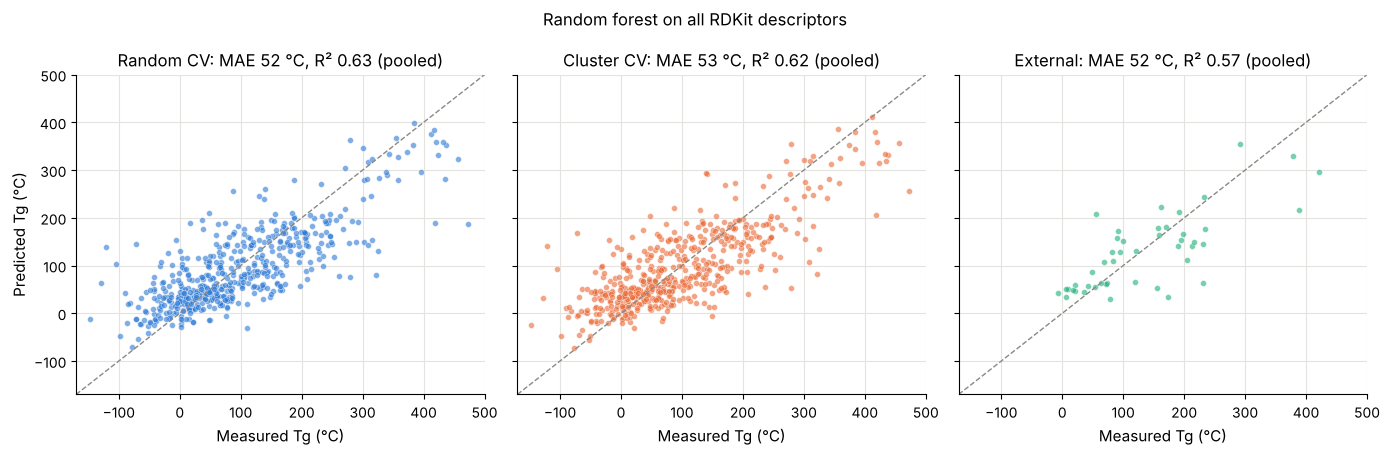

In [19]:
# Parity plots for the best model (random forest on all descriptors).
best = predictions[(predictions["model"] == "Random forest") &
                   (predictions["features"] == "All RDKit descriptors")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
lims = [-170, 500]
for ax, setting in zip(axes, order):
    d = best[best["setting"] == setting]
    m = regression_metrics(d["y_true"], d["y_pred"])
    ax.plot(lims, lims, color=NEUTRAL, lw=1, ls="--")
    ax.scatter(d["y_true"], d["y_pred"], s=18, alpha=0.6, color=SETTING_COLORS[setting],
               edgecolor="white", linewidth=0.4)
    ax.set_title(f"{setting}: MAE {m['MAE']:.0f} °C, R² {m['R2']:.2f} (pooled)")
    ax.set_xlabel("Measured Tg (°C)")
axes[0].set_ylabel("Predicted Tg (°C)")
axes[0].set(xlim=lims, ylim=lims)
fig.suptitle("Random forest on all RDKit descriptors")
fig.tight_layout()
save_figure(fig, "04_parity_rf_descriptors", FIG_DIR);

**What the table says**

- **Random forest beats Ridge in every cross-validated comparison** (the only exception is
  Morgan fingerprints on the external set, 61.9 vs 59.0 °C, well within the error bars), and all models beat the no-skill baseline
  (MAE ≈ 83-90 °C) by a wide margin.
- **All RDKit descriptors + random forest is the best combination** in every setting.
  Morgan fingerprints alone are not better than descriptors here: with ~400 training
  polymers, most substructure bits are seen only a handful of times.
- **The cluster split costs less than expected**: about 2-4 °C of MAE for the random forests.
  The fold-to-fold spread (±6-8 °C) is larger than this gap, so on this data we cannot claim a
  large generalization drop. A plausible reason is that random CV is *already* fairly
  out-of-distribution: the median nearest-neighbour similarity is only 0.50 even for random
  folds, because the 511 polymers are chemically diverse.
- **Linear models are fragile on the external set.** Ridge on ~180 descriptors falls to
  R² < 0: a few external polymers have descriptor values outside the training range and a
  linear model extrapolates them without limit, whereas a random forest's predictions stay
  within the range of training Tg values.
- The parity-plot titles use **pooled** metrics (all out-of-fold predictions together), so
  they differ slightly from the fold-averaged table. Pooled R² is higher for cluster CV
  because each cluster fold covers a narrower Tg range, which lowers per-fold R² even at the
  same MAE - one reason to rely on MAE/RMSE rather than R² when comparing splits.
- The parity plots show the usual **regression to the mean**: very high-Tg polymers are
  under-predicted. This hurts most on the external set, which contains more of them.

## 9. Uncertainty: are the error bars honest when the chemistry is new?

**Model.** Random forest (the best model above). Its raw uncertainty σ is the standard
deviation of the 300 individual tree predictions: where the trees disagree, the prediction
is less certain.

**Three ways to turn σ into a prediction interval** (all in `src/polymer_tg/uncertainty.py`):

| Method | Interval | Assumes |
|---|---|---|
| `gaussian` | ŷ ± z·σ (z = 1.64 for 90%) | tree spread is a correctly-sized standard deviation (uncalibrated) |
| `random` (conformal) | ŷ ± q·σ, q learned on **random** inner folds | test polymers resemble training polymers |
| `cluster` (conformal) | ŷ ± q·σ, q learned on **cluster** inner folds | test polymers are as new as an unseen cluster |

For conformal calibration, q is the 90% quantile of |error| / σ on polymers the model did
*not* see during fitting. Because a separate calibration hold-out would waste scarce data,
those errors come from an *inner* 5-fold CV inside each training fold; the outer test fold is
never touched.

**The test.** If an interval method is calibrated, a "90% interval" should contain the true Tg
for ~90% of test polymers - in each of the three settings. We run this for the descriptor
random forest (the main model) and the fingerprint random forest (for comparison).
This is the slowest cell (≈ 5 min): 3 settings × (1 + 2×5 inner) forests × 2 feature sets.

In [20]:
rf = make_models()["Random forest"]

uq_results = {}   # (feature set, setting) -> (predictions, calibration scores)
for feat_name in ["All RDKit descriptors", "Morgan fingerprint"]:
    X_tr_f, X_ext_f = feature_sets[feat_name]
    for setting, splits in cv_settings.items():
        uq_results[(feat_name, setting)] = run_uncertainty_experiment(
            rf, X_tr_f, y_train, splits, groups=clusters)
    uq_results[(feat_name, "External")] = run_uncertainty_experiment(
        rf, X_tr_f, y_train, None, X_test=X_ext_f, y_test=y_ext, groups=clusters)

# Attach the nearest-neighbour similarity of each test polymer (from section 7).
for (feat_name, setting), (preds, _) in uq_results.items():
    preds["similarity"] = similarity[setting][preds["test_index"]]
    preds["abs_error"] = (preds["y_true"] - preds["y_pred"]).abs()
print("done")

done


### 9a. Coverage of 90% intervals

The no-skill row is the interval "training mean ± constant" - it is what you get without any
model and tells us whether the model's intervals are actually *informative* (narrower).

In [21]:
LEVEL = 0.9
tables = []
for feat_name in ["All RDKit descriptors", "Morgan fingerprint"]:
    res = {s: uq_results[(feat_name, s)] for s in order}
    t = coverage_table(res, level=LEVEL)
    t.insert(0, "features", feat_name)
    tables.append(t)

# No-skill reference intervals for each setting.
rows = []
for setting in order:
    if setting == "External":
        cov, width = no_skill_interval(y_train, y_ext, LEVEL)
    else:
        results_folds = [no_skill_interval(y_train.values[tr], y_train.values[te], LEVEL)
                         for tr, te in cv_settings[setting]]
        cov = np.mean([c for c, _ in results_folds])
        width = np.mean([w for _, w in results_folds])
    rows.append({"features": "(none)", "setting": setting, "interval method": "no-skill",
                 f"coverage @ {LEVEL:.0%}": cov, "mean interval width (degC)": width})
tables.append(pd.DataFrame(rows))

coverage = pd.concat(tables, ignore_index=True)
coverage.pivot_table(index=["features", "interval method"], columns="setting",
                     values=[f"coverage @ {LEVEL:.0%}", "mean interval width (degC)"],
                     sort=False).reindex(columns=order, level=1).round(2)

coverage @ 90%                     mean interval width (degC)                    
setting                                    Random CV Cluster CV External                  Random CV Cluster CV External
features              interval method                                                                                  
All RDKit descriptors gaussian                  0.91       0.90     0.96                     223.15     232.02   252.17
                      random                    0.92       0.91     0.96                     228.18     237.85   247.30
                      cluster                   0.92       0.90     0.96                     228.64     228.70   250.39
Morgan fingerprint    gaussian                  0.83       0.85     0.83                     199.28     209.94   215.92
                      random                    0.90       0.92     0.96                     246.26     264.90   267.01
                      cluster                   0.91       0.90     0.93                     248.78     254.73   256.99
(none)                no-skill                  0.90       0.89     0.91                     349.39     348.27   348.73

### 9b. Calibration curves

Repeating the coverage check for every nominal level from 10% to 95% gives a calibration
curve. Points on the diagonal = calibrated; below the diagonal = intervals too narrow
(over-confident); above = too wide (under-confident).

Saved ../figures/05_calibration_curves.png


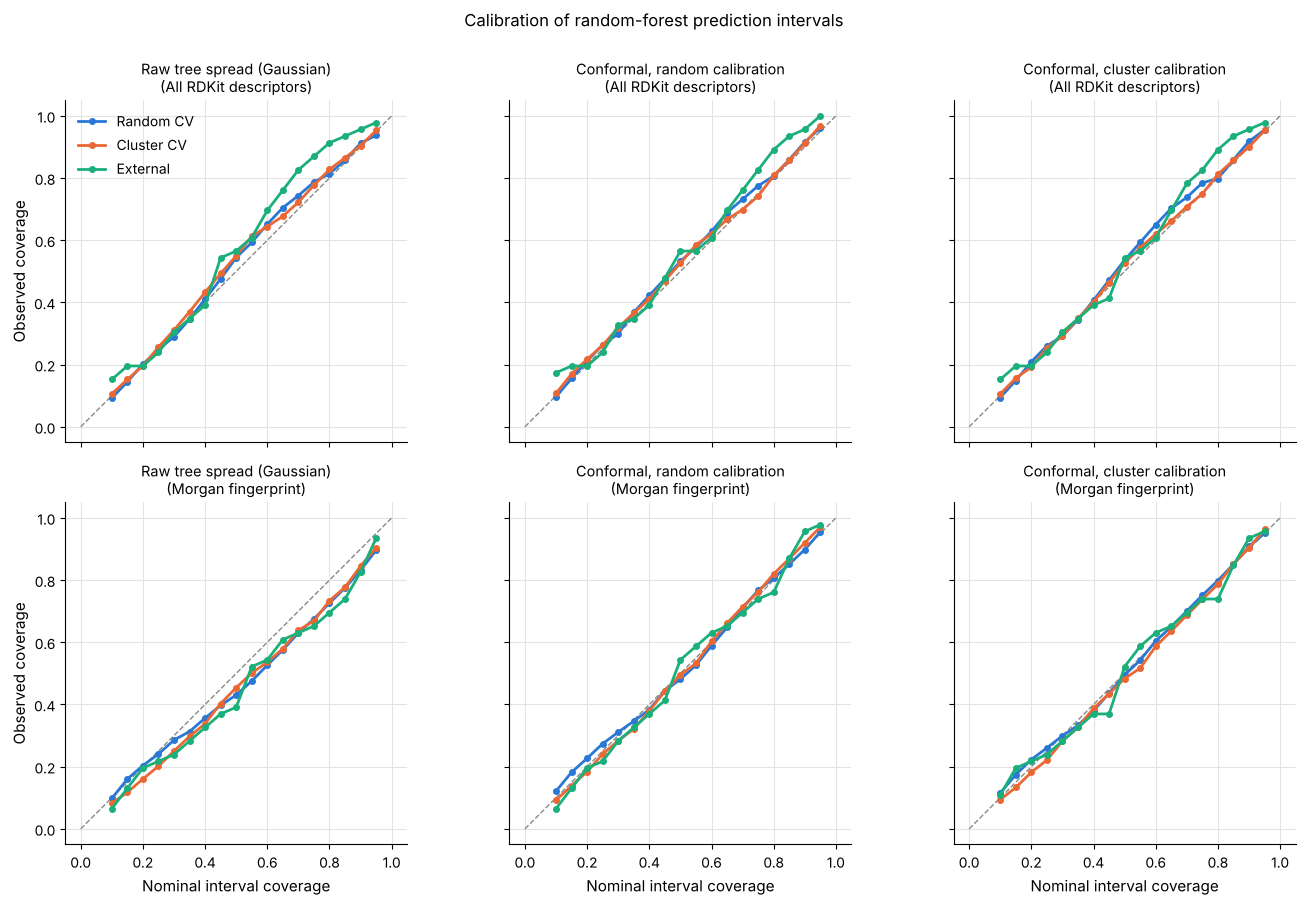

In [22]:
methods = {"gaussian": "Raw tree spread (Gaussian)",
           "random": "Conformal, random calibration",
           "cluster": "Conformal, cluster calibration"}
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
for row, feat_name in enumerate(["All RDKit descriptors", "Morgan fingerprint"]):
    for col, (method, title) in enumerate(methods.items()):
        ax = axes[row, col]
        ax.plot([0, 1], [0, 1], color=NEUTRAL, lw=1, ls="--")
        for setting in order:
            preds, scores = uq_results[(feat_name, setting)]
            curve = coverage_curve(preds, scores, method)
            ax.plot(curve["nominal"], curve["observed"], marker="o", markersize=4,
                    color=SETTING_COLORS[setting], label=setting)
        ax.set_title(f"{title}\n({feat_name})", fontsize=10.5)
        ax.set_aspect("equal")
for ax in axes[1]:
    ax.set_xlabel("Nominal interval coverage")
for ax in axes[:, 0]:
    ax.set_ylabel("Observed coverage")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Calibration of random-forest prediction intervals", y=1.0)
fig.tight_layout()
save_figure(fig, "05_calibration_curves", FIG_DIR);

### 9c. Is predicted uncertainty higher for out-of-distribution polymers?

If σ is a useful warning signal, it should **rise as a test polymer becomes less similar to
the training data**, and it should **rise with the actual error**. We check both with
Spearman rank correlation (ρ; robust to outliers and to non-linear but monotonic trends).

In [23]:
from scipy.stats import spearmanr

rows = []
for (feat_name, setting), (preds, _) in uq_results.items():
    rows.append({
        "features": feat_name, "setting": setting,
        "median sigma (°C)": preds["sigma"].median(),
        "MAE (°C)": preds["abs_error"].mean(),
        "rho(sigma, similarity)": spearmanr(preds["sigma"], preds["similarity"])[0],
        "rho(|error|, similarity)": spearmanr(preds["abs_error"], preds["similarity"])[0],
        "rho(sigma, |error|)": spearmanr(preds["sigma"], preds["abs_error"])[0],
    })
pd.DataFrame(rows).round(2)

,features,setting,median sigma (°C),MAE (°C),"rho(sigma, similarity)","rho(|error|, similarity)","rho(sigma, |error|)"
0,All RDKit descriptors,Random CV,66.33,51.71,-0.30,-0.04,0.27
1,All RDKit descriptors,Cluster CV,69.37,52.68,-0.30,-0.07,0.26
2,All RDKit descriptors,External,72.02,51.95,-0.10,-0.15,0.32
3,Morgan fingerprint,Random CV,56.34,54.40,-0.23,0.01,0.19
4,Morgan fingerprint,Cluster CV,58.98,57.30,-0.18,-0.03,0.23
5,Morgan fingerprint,External,66.51,61.91,0.14,-0.11,0.47


Saved ../figures/06_uncertainty_vs_similarity.png


,n,mean_sigma,MAE
similarity bin,,,
"(0.0, 0.3]",177,78.9,57.5
"(0.3, 0.4]",265,72.3,53.9
"(0.4, 0.5]",234,67.7,49.4
"(0.5, 0.6]",188,67.2,50.1
"(0.6, 1.0]",204,61.9,50.4


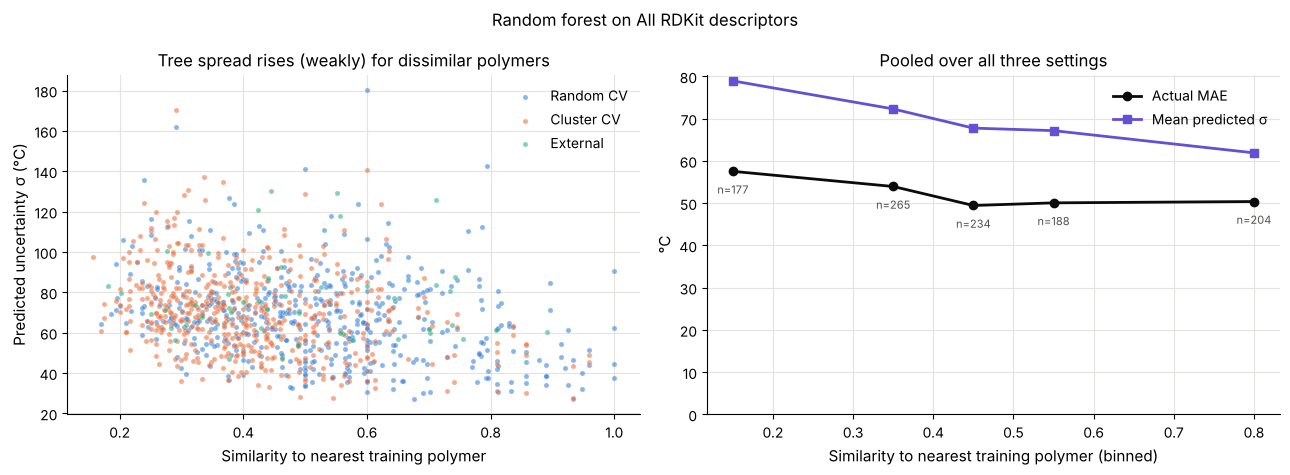

In [24]:
feat_name = "All RDKit descriptors"
pooled = pd.concat([uq_results[(feat_name, s)][0].assign(setting=s) for s in order],
                   ignore_index=True)
sim_bins = [0, 0.3, 0.4, 0.5, 0.6, 1.0]
pooled["similarity bin"] = pd.cut(pooled["similarity"], sim_bins)
binned = pooled.groupby("similarity bin", observed=True).agg(
    n=("sigma", "size"), mean_sigma=("sigma", "mean"), MAE=("abs_error", "mean"))
bin_centers = [(iv.left + iv.right) / 2 for iv in binned.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
for setting in order:
    d = pooled[pooled["setting"] == setting]
    ax.scatter(d["similarity"], d["sigma"], s=14, alpha=0.55, color=SETTING_COLORS[setting],
               edgecolor="white", linewidth=0.3, label=setting)
ax.set(xlabel="Similarity to nearest training polymer", ylabel="Predicted uncertainty σ (°C)",
       title="Tree spread rises (weakly) for dissimilar polymers")
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(bin_centers, binned["MAE"], marker="o", color="#0b0b0b", label="Actual MAE")
ax.plot(bin_centers, binned["mean_sigma"], marker="s", color="#6250d6", label="Mean predicted σ")
for x, (n, mae) in zip(bin_centers, zip(binned["n"], binned["MAE"])):
    ax.annotate(f"n={n}", (x, mae), textcoords="offset points", xytext=(0, -16),
                ha="center", fontsize=8, color="#52514e")
ax.set(xlabel="Similarity to nearest training polymer (binned)", ylabel="°C",
       title="Pooled over all three settings", ylim=(0, None))
ax.legend(loc="upper right")
fig.suptitle(f"Random forest on {feat_name}")
fig.tight_layout()
save_figure(fig, "06_uncertainty_vs_similarity", FIG_DIR)
binned.round(1)

**What the uncertainty results say**

- **Coverage holds up under shift for the descriptor forest.** Its 90% intervals cover
  ~90-92% in random *and* cluster CV, and over-cover (~96%) on the external set, for all
  three interval methods. Under this degree of chemical dissimilarity the intervals did not
  break.
- **The raw tree spread is only calibrated by luck.** For the fingerprint forest the raw
  Gaussian intervals are over-confident (~83-85% coverage for a nominal 90%) in every setting.
  Conformal calibration fixes this in all three settings; calibrating on clusters gives
  slightly narrower intervals than random calibration for the external set at similar
  coverage. Raw tree variance should not be trusted without a calibration step.
- **σ does rise for out-of-distribution polymers**: ρ(σ, similarity) ≈ -0.3 for the
  descriptor forest in both CV settings (weaker, -0.1, on the 46 external polymers). In the
  binned plot σ grows somewhat more steeply than the actual error as similarity drops, which
  is why interval coverage does not collapse on dissimilar polymers. (σ is a standard
  deviation, so it is expected to sit above the MAE: for normally distributed errors
  MAE ≈ 0.8σ.)
- **But σ is only a weak per-polymer error predictor** (ρ(σ, |error|) ≈ 0.25-0.3 for the
  descriptor forest), and the intervals are **wide**: ~230 °C for 90% coverage, versus
  ~350 °C for the no-skill interval.
  The intervals are honest, but they say "this polymer's Tg is somewhere in a 230 °C window",
  which is useful for ranking/flagging, not for precise prediction.

## 10. Interpretability: which descriptors drive the predictions?

SHAP values split each prediction into contributions from each feature (in °C), relative to
the average prediction. `TreeExplainer` computes them exactly for tree models. We fit the
random forest on all training polymers with all descriptors and show the 15 features with
the largest average |SHAP|.

*Caveat:* many RDKit descriptors are strongly correlated with each other. When two features
carry the same information, the forest may use either one, and the credit is split between
them in an arbitrary way. Read the top features as "this kind of information matters", not
as "this exact descriptor is the cause".

In [25]:
import shap

rf_full = make_models()["Random forest"].fit(X_full, y_train)
explainer = shap.TreeExplainer(rf_full)
shap_values = explainer.shap_values(X_full)

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=X_full.columns)
top15 = mean_abs_shap.sort_values(ascending=False).head(15)
top15.round(1).to_frame("mean |SHAP| (°C)")

,mean |SHAP| (°C)
FractionCSP3,52.9
SlogP_VSA8,14.6
VSA_EState4,5.4
NumRotatableBonds,5.3
SPS,4.4
VSA_EState7,4.1
VSA_EState1,3.6
RingCount,3.2
FpDensityMorgan3,2.5
Kappa3,2.3


Saved ../figures/07_shap_summary.png


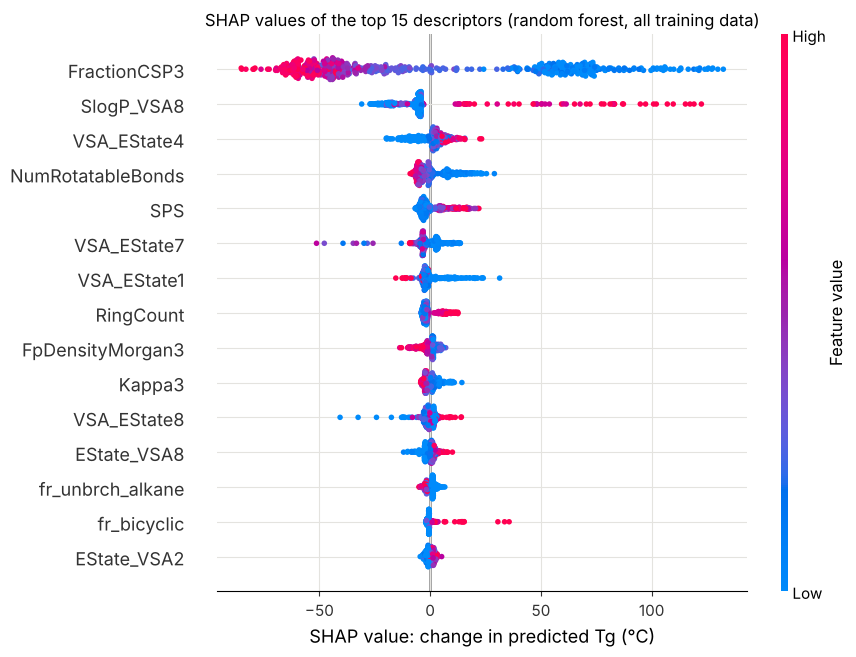

In [26]:
plt.figure()
shap.summary_plot(shap_values, X_full, max_display=15, show=False, plot_size=(9, 6.5))
fig = plt.gcf()
fig.axes[0].set_title("SHAP values of the top 15 descriptors (random forest, all training data)")
fig.axes[0].set_xlabel("SHAP value: change in predicted Tg (°C)")
save_figure(fig, "07_shap_summary", FIG_DIR);

Saved ../figures/08_shap_fraction_csp3.png


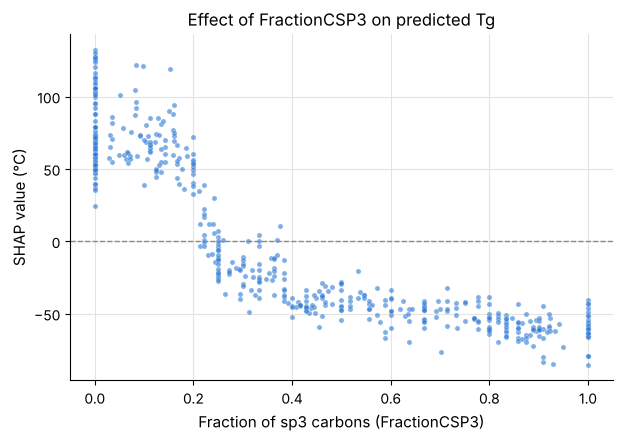

In [27]:
# Dependence plot for the dominant feature: how predicted Tg changes with fraction_csp3.
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(X_full["FractionCSP3"], shap_values[:, X_full.columns.get_loc("FractionCSP3")],
           s=14, alpha=0.6, color=SETTING_COLORS["Random CV"], edgecolor="white", linewidth=0.3)
ax.axhline(0, color=NEUTRAL, lw=1, ls="--")
ax.set(xlabel="Fraction of sp3 carbons (FractionCSP3)",
       ylabel="SHAP value (°C)", title="Effect of FractionCSP3 on predicted Tg")
save_figure(fig, "08_shap_fraction_csp3", FIG_DIR);

**Reading the SHAP plots.** `FractionCSP3` dominates by a wide margin: polymers with mostly
sp3 (saturated, flexible) carbon get a large negative contribution, and the effect is roughly
monotonic. This matches polymer physics - aliphatic, flexible backbones have low Tg; aromatic,
rigid ones have high Tg. Several of the following descriptors (`NumRotatableBonds`,
`RingCount`, `fr_unbrch_alkane`, `Kappa3`) encode the same chain flexibility/rigidity idea.
The `VSA_EState` and `SlogP_VSA` descriptors bin molecular surface area by atomic
electronic state or by atomic contribution to logP, a rough proxy for polarity and
intermolecular interactions; their exact chemical meaning (e.g. which atom types fall into
`SlogP_VSA8`) should be checked in the RDKit documentation before interpreting them further. The model has essentially learned
the familiar "stiffness and interactions raise Tg" rules from the data.

## 11. Conclusions

1. **Generalization to dissimilar chemistry.** On this dataset, holding out whole
   chemical clusters makes the best model only slightly worse than random CV
   (MAE ≈ 54 vs 52 °C for the descriptor random forest; R² 0.56 vs 0.62). The gap is
   smaller than the fold-to-fold spread. Random CV on a small, diverse polymer set is
   already a fairly hard test, so the "random split is optimistic" effect is real but modest
   here.
2. **The external set behaves differently.** It is only mildly dissimilar in chemistry but
   shifted to higher Tg; random-forest error there is similar to CV, whereas the
   high-dimensional linear model fails (R² < 0) because it extrapolates.
3. **Calibration.** Conformal-calibrated random-forest intervals keep close to their nominal
   coverage in all three settings. The raw tree spread happened to be well-sized for the
   descriptor forest, but was over-confident for the fingerprint forest, so a calibration
   step is necessary.
4. **OOD awareness.** Predicted uncertainty increases for polymers that are dissimilar to
   the training set, which is the desired behaviour - but it is a weak predictor of the error
   of an individual polymer, and intervals are wide (≈ 230 °C at 90%, compared with ≈ 350 °C
   for a no-skill interval).
5. **Interpretability.** The dominant learned rule is "more sp3 carbon → lower Tg", plus
   other flexibility and polarity descriptors, consistent with polymer physics.

**Limitations.** 511 training polymers; a single clustering cutoff; 46 external polymers
(bootstrap error bars are wide); no hyperparameter tuning (deliberately, to avoid
overfitting the small data); random-forest predictions cannot go beyond the training
Tg range. Ideas for further work are listed in `README.md`.